<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS10/lab2_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 — Persiapan library dan dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
print('Ukuran data:', X.shape)
display(X.head())

Ukuran data: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Langkah 2 — Eksplorasi label dan fitur

Nama kelas: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


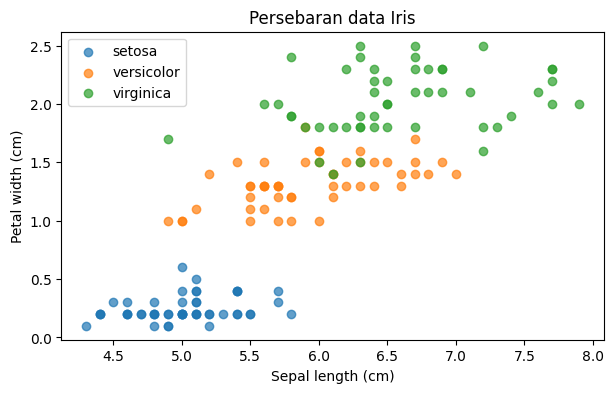

In [2]:
print('Nama kelas:', list(iris.target_names))
print(pd.Series(y).map(dict(enumerate(iris.target_names))).value_counts())
fig, ax = plt.subplots(figsize=(7, 4))
for k, name in enumerate(iris.target_names):
    mask = (y == k)
    ax.scatter(X.loc[mask, 'sepal length (cm)'], X.loc[mask, 'petal width (cm)'],
               label=name, alpha=0.7)
ax.set(xlabel='Sepal length (cm)', ylabel='Petal width (cm)', title='Persebaran data Iris')
ax.legend()
plt.show()

## Langkah 3 — Bagi data training dan testing
Gunakan stratifikasi agar proporsi setiap kelas tetap seimbang.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Data train:', len(X_train), '| data test:', len(X_test))

Data train: 120 | data test: 30


## Langkah 4 — Bangun dan latih MLP
`StandardScaler` ditempatkan dalam pipeline agar scaler dipelajari **hanya** dari data train.

In [4]:
model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu',
                  solver='adam', max_iter=800, random_state=42,
                  early_stopping=False)
)
model.fit(X_train, y_train)
print('Jumlah iterasi:', model.named_steps['mlpclassifier'].n_iter_)

Jumlah iterasi: 585


## Langkah 5 — Prediksi dan evaluasi

Akurasi test: 96.67%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



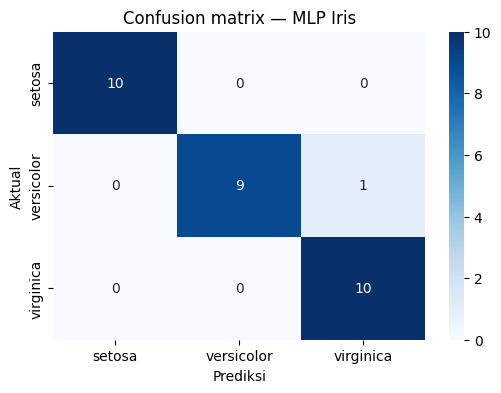

In [5]:
y_pred = model.predict(X_test)
print(f'Akurasi test: {accuracy_score(y_test, y_pred):.2%}')
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion matrix — MLP Iris')
plt.show()

## Langkah 6 — Kurva loss pelatihan

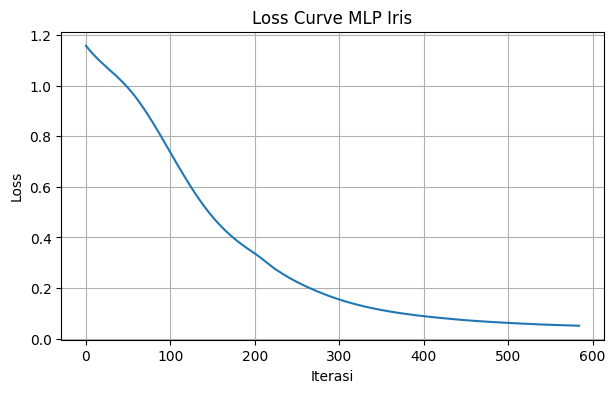

In [6]:
mlp = model.named_steps['mlpclassifier']
plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_)
plt.xlabel('Iterasi'); plt.ylabel('Loss')
plt.title('Loss Curve MLP Iris'); plt.grid(True); plt.show()

## Kesimpulan

- ANN/MLP menggunakan sejumlah neuron di hidden layer untuk belajar hubungan nonlinier.
- **Akurasi test** lebih informatif daripada akurasi train karena mengukur kemampuan generalisasi.
- Performa dipengaruhi pemilihan fitur, arsitektur, learning rate, dan jumlah iterasi.